# 1. 静态分支

## 1.1 顺序结构

### 1.1.1 add_edge
`add_edge` 用于在两个节点之间添加一条有向边。边是图结构中最基本的元素之一，节点之间的执行顺序、分支跳转以及循环控制，最终都依赖节点和边共同表达。

因此，在 LangGraph 中，基础的控制流结构都可以通过 `add_edge` 进行构建。

D:\ProgramData\miniconda3\envs\langgraph\Lib\site-packages\langgraph\cache\base\__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


{'username': '小任', 'greeting': 'Dear 小任', 'output': 'Dear 小任，你好！'}


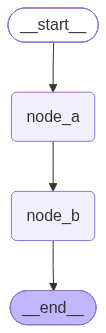

In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"username": "小任"})
print(res)

from IPython.display import display

display(graph)

在上述示例中，图的执行流程如下：
```
START -> node_a -> node_b -> END
```
其中：

`START -> node_a` 表示图从 `node_a` 开始执行；

`node_a -> node_b` 表示 `node_a` 执行完成后，继续执行 `node_b`；

`node_b -> END` 表示 `node_b` 执行完成后，图进入结束状态。

### 1.1.2 add_sequence
如果需要构建一组按顺序执行的节点，也可以使用 `add_sequence`。

`add_sequence` 支持传入一个可执行对象列表。LangGraph 会按照列表顺序依次添加节点，并在相邻节点之间自动添加边。默认情况下，函数名会被用作节点名称。


{'username': '小任', 'greeting': 'Dear 小任', 'output': 'Dear 小任，你好！'}


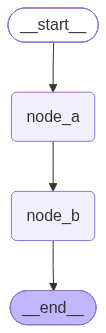

In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_edge(START, "node_a")
builder.add_sequence([node_a, node_b])
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"username": "小任"})
print(res)

from IPython.display import display

display(graph)

上述代码中：
```python
builder.add_sequence([node_a, node_b])
```

大致等价于：
```python
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge("node_a", "node_b")
```
因此，完整执行流程仍然是：
```
START -> node_a -> node_b -> END
```

相比手动调用多次 add_node 和 add_edge，add_sequence 更适合用于构建简单的线性执行流程。

### 1.1.3 省略指向 END 的边
在 LangGraph 中，图的终止并不完全依赖某个真实执行的特殊节点。

从运行机制上看，LangGraph 会在每个 `SuperStep` 开始时，根据当前发生更新的 `Channel` 以及节点之间的触发关系，计算本轮需要执行的任务列表。如果没有新的节点被激活，也就没有新的任务需要执行，图运行自然结束。

需要注意的是，`END` 并不是运行阶段真正执行的节点。也就是说，指向 `END` 的边不会像指向普通节点的边那样，触发一个真实的节点任务。它更多用于表达图结构中的“终止语义”：当前路径执行到这里即可结束。

因此，在一些简单的线性流程中，即使省略指向 `END` 的边，最后一个节点执行完成后，如果没有后续节点被触发，图也可以正常结束。

{'username': '小黄', 'greeting': 'Dear 小黄', 'output': 'Dear 小黄，你好！'}


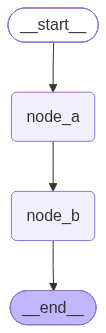

In [3]:
from langgraph.graph import StateGraph, START
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")

graph = builder.compile()
res = graph.invoke({"username": "小黄"})
print(res)

from IPython.display import display

display(graph)

在这个例子中，虽然没有显式添加：
```python
builder.add_edge("node_b", END)
```
但是 `node_b` 执行完成后，没有新的节点被触发，图运行会自然结束。

不过，可以省略指向 `END` 的边，并不表示 `END` 没有意义。

显式添加 `END` 边可以让图结构更加完整，也能更清晰地表达“流程到此结束”的语义。尤其是在分支、条件跳转、循环退出等场景中，显式指向 `END` 通常更利于阅读和维护。

和 `END` 不同，`START` 通常不能省略。因为 `START` 不只是一个语义上的起点标记，它还用于告诉 LangGraph：图运行时应当从哪些节点开始执行。也就是说，下面这条边是启动图执行的关键：

```python
builder.add_edge(START, "node_a")
```
如果没有从 `START` 出发的边，或者没有通过其他方式指定入口节点，LangGraph 就无法确定图的初始执行节点。

因此，在实际开发中，建议保留指向 `END` 的边。虽然在某些简单流程中省略这些边也能正常运行，但显式添加它们，可以让图结构更加完整、语义更加清晰，便于后续维护。

## 1.2 分支结构

### 1.2.1 并行节点

In [4]:
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END

from langchain.messages import HumanMessage
from typing import TypedDict, Literal, Sequence
from rich import print as rprint
from loguru import logger

from dotenv import load_dotenv
load_dotenv(override=True)


model = ChatOpenAI(
    model="gpt-3.5-turbo",
    base_url="https://api.closeai-asia.com/v1",  # closeai官方中转地址
    timeout=60
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    ci: str
    joke: str
    content_type: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(content=f"请写一首关于{state['topic']}的七言绝句。")]).content
    return {"poem": poem}

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(content=f"请写一个关于{state['topic']}的笑话。")]).content
    return {"joke": joke}

def node_c(state: OverAllState) -> OverAllState:
    ci = model.invoke([HumanMessage(content=f"请写一个关于{state['topic']}的词。")]).content
    return {"ci": ci}

def audit_node(state: OverAllState) -> OverAllState:
    logger.info(f"任务节点已经全部执行完毕，诗{'已生成' if state['poem'] else '未生成'}，笑话{'已生成' if state['joke'] else '未生成'}，词{'已生成' if state['ci'] else '未生成'}")
    return state


{
    'topic': '小猫',
    'poem': '软簌猫儿睡梦中，咪咪喵喵意无穷。\n顽皮调皮如小孩，撒娇卖萌笑容红。',
    'joke': '为什么小猫在床底下笑得那么开心？因为它发现了一个“床下世界”，里面有无数的玩具和积攒已久的毛线球！'
}

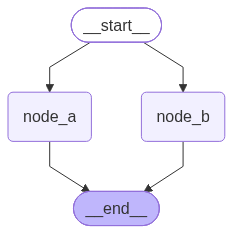

In [5]:
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫"})
rprint(result)

from IPython.display import display
display(graph)

上述案例中，`node_a` 和 `node_b` 都由 START 触发。图运行时，二者会在同一个超步中被调度，它们各自读取当前状态并独立执行。

需要注意的是：

- 这里的“并行”主要指调度语义上的并行；两个节点之间没有先后依赖；
- 它们的输出会在当前超步执行完成后统一合并到状态中；
- 如果两个节点写入同一个状态字段，则该字段通常需要配置合适的 `Reducer`，否则可能出现状态更新冲突，抛出 `InvalidUpdateError` 异常

{
    'topic': '小猫',
    'poem': '毛茸茸小猫咪，眼神清澈又可爱。\n爪子抓来玩具碎，纤细身躯快乐开。',
    'joke': '为什么小猫喜欢玩钓鱼游戏？\n因为它们总是想抓住“鱼”果！哈哈！'
}

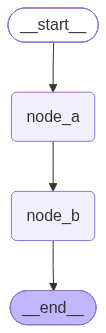

In [6]:
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫"})
rprint(result)

from IPython.display import display
display(graph)

### 1.2.2 条件分支

`StateGraph` 提供了 `add_conditional_edges` 方法，用于从某个上游节点出发，根据运行时状态选择下游节点。

方法签名如下：
```python
def add_conditional_edges(
    self,
    source: str,
    path: Callable[..., Hashable | Sequence[Hashable]]
    | Callable[..., Awaitable[Hashable | Sequence[Hashable]]]
    | Runnable[Any, Hashable | Sequence[Hashable]],
    path_map: dict[Hashable, str] | list[str] | None = None,
) -> Self:
    ...
```
不考虑 self，核心参数有三个：
- `source`：条件分支的起始节点；
- `path`：路由规则，是一个可执行对象，通常是函数
- `path_map`：路由规则的返回值到真实节点名之间的映射关系。

其中，`path` 的返回值表示跳转的目标节点，可以是：
- 字符串或特殊对象 `END` 表示的单个目标；
- 字符串或特殊对象 `END` 表示的多个目标组成的序列；

`path_map`
- 可以省略，即取默认值 None，此时 path 返回值中出现的字符串必须是合法的节点名称。
- 可以是字典，维护 path 返回值和真实节点的映射。
- 也可以是列表，如下
```python
path_map=["node_a", "node_b", "node_c"]
# 相当于
path_map={
    "node_a": "node_a",
    "node_b": "node_b",
    "node_c": "node_c",
}
```
此时也要求 path 返回值中出现的字符串必须是合法的节点名称。

{
    'topic': '小猫',
    'joke': '为什么小猫会笑得肚子疼？\n\n因为它听了一个“猫”抓耳挠腮的笑话！哈哈哈！',
    'content_type': ''
}

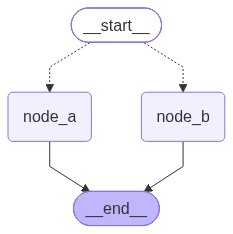

In [7]:
def route(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "node_a"
    else:
        return "node_b"


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)

builder.add_conditional_edges(
    source=START,
    path=route
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫", "content_type": ""})
# result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

{
    'topic': '小猫',
    'joke': '为什么小猫喜欢玩躲猫猫游戏？\n\n因为它们觉得自己是“冠军藏猫猫”！哈哈！😸',
    'content_type': ''
}

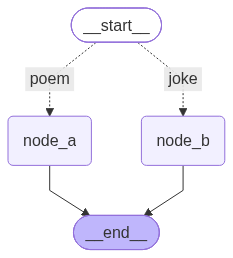

In [8]:
def route(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "poem"
    else:
        return "joke"


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)

builder.add_conditional_edges(
    source=START,
    path=route,
    path_map={"poem": "node_a", "joke": "node_b"}
)

builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫", "content_type": ""})
# result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

同时路由至多个节点

`add_conditional_edges`也支持一次路由到多个节点

{
    'topic': '小猫',
    'ci': 
'小猫，是一种可爱的动物。它们有着柔软的毛发和灵动的眼睛，总是能够让人忍不住想要轻轻抚摸它们。小猫喜欢玩耍，喜欢追逐
着蝴蝶和蜜蜂，尽情享受生活的快乐。它们也很亲近人类，常常蹲在人的身边，发出咕噜咕噜的声音，表示对主人的依赖和爱。小
猫是一种最能够温暖人心的生物，它们的存在让世界变得更加美好。',
    'joke': '为什么小猫在学校里很受欢迎？\n\n因为它们总是抓得一手好鱼！哈哈哈！',
    'content_type': ''
}

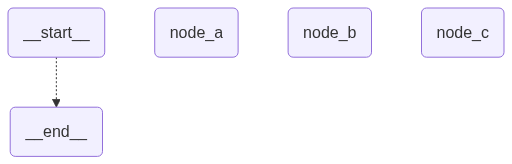

In [9]:
def route(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a", "node_c"]
    else:
        return ["node_b", "node_c"]


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_conditional_edges(
    source=START,
    path=route
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫", "content_type": ""})
# result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

{
    'topic': '小猫',
    'poem': '毛绒绒小猫趣，圆脸咪咪眼瞳如玉。\n软软爪儿轻抚手，温顺顺猫咪来相伴。',
    'ci': 
'小猫，一只顽皮可爱的动物，身上覆盖着柔软的绒毛，眼睛明亮有神，尾巴灵活地摆动着。它们喜欢在阳光下打盹，喜欢捉追逐弹
珠，喜欢躲在角落里偷偷观察周围的一切。小猫总是充满好奇和活力，让人忍不住想要把它们抱在怀里，感受它们温暖的身体和轻
柔的呼吸。无论是矫捷的跳跃还是温柔的撒娇，小猫都能够让我们感受到生活的美好和快乐。它们是人类最忠诚的伙伴，陪伴我们
度过孤独的时光，给予我们无尽的温暖和安慰。小猫，就像一颗闪亮的五彩斑斓的宝石，永远散发着独特的光芒，让人们怦然心动
，无法自拔。',
    'content_type': '诗'
}

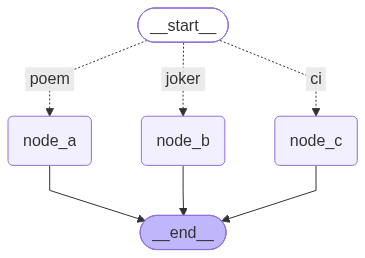

In [10]:
def route(state: OverAllState) -> Sequence[Literal["poem", "joker", "ci"]]:
    if "诗" in state["content_type"]:
        return ["poem", "ci"]
    else:
        return ["joker", "ci"]


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_conditional_edges(
    source=START,
    path=route,
    path_map={"poem": "node_a", "joker": "node_b", "ci": "node_c"}
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
# result = graph.invoke({"topic": "小猫", "content_type": ""})
result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

{
    'topic': '小猫',
    'poem': '柔媚小猫躲在花丛里，清晨嬉戏快乐无比。 \n软毛绒球眼神含情，顽皮调皮呼朋引伴。',
    'ci': 
'小猫，是一种可爱的动物，身形娇小灵活，毛色各异，有着浓密的毛发和明亮的眼睛。小猫天性调皮活泼，喜欢玩耍和捉弄周围的
东西，常常让人忍俊不禁。它们喜欢依偎在主人身边，发出咕噜咕噜的声音，表示对主人的喜爱与依赖。小猫的动作优雅可爱，总
给人一种温暖与舒适的感觉。无论是在家中的沙发上躺着、窗台上晒太阳，还是在院子里追逐嬉戏，小猫总是能带来无限的快乐与
欢乐。无论是在现实生活中，还是在各种媒体中，小猫都是备受喜爱和追捧的宠物之一。它们的可爱和俏皮形象，总能让我们心情
愉悦，忘却烦恼，感受到生活的美好与快乐。无论是静静的看着小猫打盹，还是陪伴小猫玩耍，都能让人感受到一份无限的温情和
幸福。小猫，是人类的好朋友，也是我们生活中的一份美好。',
    'content_type': '诗'
}

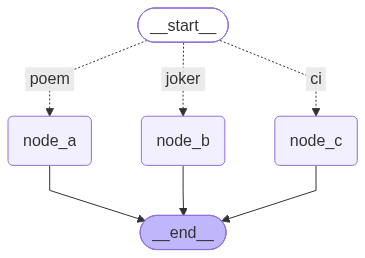

In [11]:
def route(state: OverAllState) -> Sequence[Literal["poem", "joker", "ci"]]:
    if "诗" in state["content_type"]:
        return ["poem", "ci"]
    else:
        return ["joker", "ci"]


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_conditional_edges(
    source=START,
    path=route,
    path_map={"poem": "node_a", "joker": "node_b", "ci": "node_c"}
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
# result = graph.invoke({"topic": "小猫", "content_type": ""})
result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)

### 1.2.3 defer node execution

某些情况下，我们希望在所有常规任务节点执行完毕后，再进行日志、审计等收尾工作

此时可以在添加节点时设置`defer=True`，如下：
```python
builder.add_node("audit_node", audit_node, defer=True)
```

`defer=True` 的含义是：

当前节点不会在其被触发后立即执行，而是被延迟到常规图运行流程结束后，再在额外的超步中触发执行。

这类节点适合用于：

- 日志记录；
- 审计检查；
- 结果汇总；
- 收尾清理；
- 统一校验前面节点是否已完成。

**底层原理**

1. 编译阶段：使用特殊 Channel
    - LangGraph 在编译状态图时，会为边创建对应的 `Channel`。

    - 此时会根据节点的 defer 属性创建不同类型的 Channel，如下。
    ```python
   self.channels[branch_channel] = (
       LastValueAfterFinish(Any)
       if node.defer
       else EphemeralValue(Any, guard=False)
   )
    ```
    `defer` 默认值为 `False`

    对于普通节点，边对应的通道类型是 `EphemeralValue`，可以理解为普通临时通道；而对于 `defer=True` 的节点，边对应的通道类型是特殊的 `LastValueAfterFinish`。

2. 常规运行阶段-写入但不触发
    - 在图运行过程中，每个节点执行完成后，会向其下游边对应的 `Channel` 写入数据。
    - 常规的 Channel 在运行开始后处于可用状态，被写入后记录在 `updated_channels` 列表中，从而在下一个超步中触发下游节点的执行。
    - 但是，`LastValueAfterFinish` 类型的通道起初是不可用的，首次被写入时不会添加到 `updated_channels` 列表中，下游节点自然不会被触发。
3. 常规流程结束后：调用`finish()`唤醒延迟节点
    - LangGraph 底层用 `trigger_to_nodes` 维护了 边的 `Channel` -> 节点 的映射，是一个字典。
    - 在每个超步结束后，运行时会根据 `updated_channels` 判断是否还有新的节点需要被触发。
    - 如果 `updated_channels` 和 `trigger_to_nodes` 的 key 没有交集，说明当前没有新的普通节点需要继续执行，常规运行流程已结束。
    - 此时，LangGraph 运行时会调用所有 `Channel` 的 `finish()` 方法。
    - 对于普通 `Channel` ，`finish()` 通常不会产生新的触发效果；但对于 LastValueAfterFinish 类型通道，首次调用 `finish()` 时，会将内部的 `finished` 标记设置为 `True`，并返回 `True`。
    - 一旦 `finished=True`，该通道的 `is_available()` 就会变为 True。
    - 于是，原本被延迟的通道会被加入 `updated_channels`，从而在额外的超步中触发对应的 `defer` 节点。
4. 总结
因此，`defer=True` 的运行机制可以概括为：

> 触发边的 `Channel` 为特殊类型，首次写入不触发；常规流程结束后，特殊通道 `finish()`；通道变为可用；从而触发延迟节点，后者在额外超步中执行。

2026-10-15 10:18:42.174 | INFO     | __main__:audit_node:39 - 任务节点已经全部执行完毕，诗已生成，笑话已生成，词已生成


{
    'topic': '小猫',
    'poem': '软毛娇小似云烟，爪牙玲珑似拨弦。\n顽皮调皮调皮爽，撒娇卖萌乐无边。',
    'ci': 
'小猫，软绵绵的毛发，灵活的身姿，调皮可爱的眼神，总是让人忍不住想要抚摸它们的小脑袋。它们在家里悠闲地蜷缩着，或者在
户外追逐玩耍，总是能给人带来无尽的欢乐。小猫的小脚丫轻轻地踏在地上，发出清脆的声响，仿佛是自带音乐的小舞者。即使它
们淘气调皮，但一旦眯起眼睛，发出懒洋洋的呼噜声，便能让人心情舒畅，忘记一切烦恼。小猫，永远是人类忠实的好朋友，带给
我们无尽的温暖与欢乐。',
    'joke': '为什么小猫喜欢玩捉迭戏？\n\n因为它们觉得自己很“捉迭”（可爱）！哈哈哈！'
}

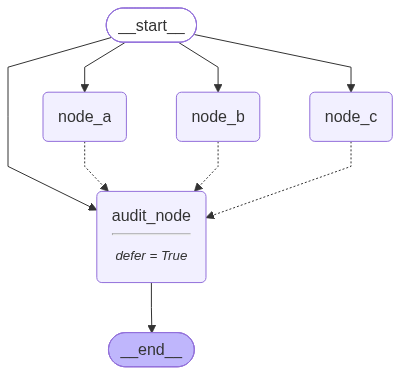

In [12]:
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("audit_node", audit_node, defer=True)

builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge(START, "node_c")
builder.add_edge(START, "audit_node")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)
builder.add_edge("audit_node", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫"})
rprint(result)

from IPython.display import display
display(graph)

`defer=True` 适合“最后执行”的收尾节点。

它的本质是通过特殊的 `Channel` 控制触发时机：

- 编译阶段为延迟节点创建 `LastValueAfterFinish` 类型通道；
- 常规运行阶段该通道可以被写入，但不可用，不会触发下游节点；
- 常规流程结束后调用通道的 `finish()` 方法；
- `finish()` 首次生效后将通道标记为可用；
- 延迟节点在额外超步中被触发执行。

> 因此， `defer=True` 将节点的触发信号延迟释放，使该节点在常规流程结束后执行。